# Build a joint state and test its correlations

A single qubit has two amplitudes. Two qubits have four amplitudes, one for each **joint** basis outcome. This notebook builds product states and a Bell state, then separates quantum coherence from a classical source of correlated bits.

**Ordering:** the first qubit, `q0`, is the **leftmost** bit and the most significant bit. The four entries are `[|00⟩, |01⟩, |10⟩, |11⟩]`; index `2` means `q0 = 1, q1 = 0`. A tensor product `a ⊗ b`, implemented by `np.kron(a, b)`, places the amplitudes of `q0` first and those of `q1` second. Never infer this convention from another library: some libraries display qubits in the opposite order.

**Model boundary:** two ideal qubits, pure states and explicitly defined classical ensembles, with local X or Z measurements. Comparing these few settings is not a universal entanglement test, a complete state reconstruction, or a CHSH/Bell-inequality experiment. We will show exactly where the comparison works and where it misses entanglement.

**Reproduce locally:** install `notebooks/requirements.txt` with Python 3.10 or newer, open the downloaded `.ipynb` in Jupyter, then **Restart Kernel and Run All**. The website displays the saved outputs of a successful run.

## 1. Prepare four-entry states

A state is normalized when the squared magnitudes of all its amplitudes sum to one. The complex amplitude at index `k` gives Z/Z outcome `k` with probability equal to its squared magnitude. **Z/Z** means measure both qubits in Z; **X/X** means measure both in X.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8.2, 3.8), "figure.dpi": 120,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#24354b", "text.color": "#24354b",
    "xtick.color": "#44556c", "ytick.color": "#44556c",
    "font.size": 11, "axes.titleweight": "bold",
    "axes.grid": True, "grid.alpha": 0.16,
    "grid.color": "#718198", "lines.linewidth": 2.4,
    "savefig.bbox": "tight",
})
BLUE, GREEN, AMBER = "#3c6db3", "#27836d", "#b87920"
TOLERANCE = 1e-10


def assert_state(state):
    state = np.asarray(state, dtype=complex)
    if state.shape not in ((2,), (4,)):
        raise ValueError("This model supports one or two qubits.")
    if not np.isfinite(state).all():
        raise ValueError("All amplitudes must be finite.")
    if not np.isclose(np.vdot(state, state).real, 1, atol=TOLERANCE, rtol=0):
        raise ValueError("The state must already be normalized.")
    return state


def probabilities(state):
    return np.abs(assert_state(state)) ** 2


print(f"Ready: NumPy {np.__version__}, Matplotlib {matplotlib.__version__}")
print("Ideal finite-dimensional model; every plot is computed by this notebook.")

labels = ["00", "01", "10", "11"]
zero = np.array([1, 0], dtype=complex)
one = np.array([0, 1], dtype=complex)
I = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
print("Joint basis order:", labels, "; q0 is the leftmost bit.")

Ready: NumPy 2.3.5, Matplotlib 3.10.8
Ideal finite-dimensional model; every plot is computed by this notebook.
Joint basis order: ['00', '01', '10', '11'] ; q0 is the leftmost bit.


## 2. Form a product state with a tensor product

Prepare `q0 = [sqrt(0.7), sqrt(0.3)]` and `q1 = [sqrt(0.2), i sqrt(0.8)]`. The joint product state has amplitudes `[a0b0, a0b1, a1b0, a1b1]`, where `a` names `q0`'s vector and `b` names `q1`'s vector.

For this independently prepared product state, the joint Z probability factors: `P(i, j) = P(q0 = i) P(q1 = j)`. For example `P(01) = 0.7 × 0.8`. Calculate all four probabilities before running. The phase on `q1` survives in the amplitudes, although it does not affect this Z/Z distribution.

Product amplitudes [00, 01, 10, 11]: [0.374166+0.j       0.      +0.748331j 0.244949+0.j
 0.      +0.489898j]
Joint Z probabilities: [0.14 0.56 0.06 0.24]


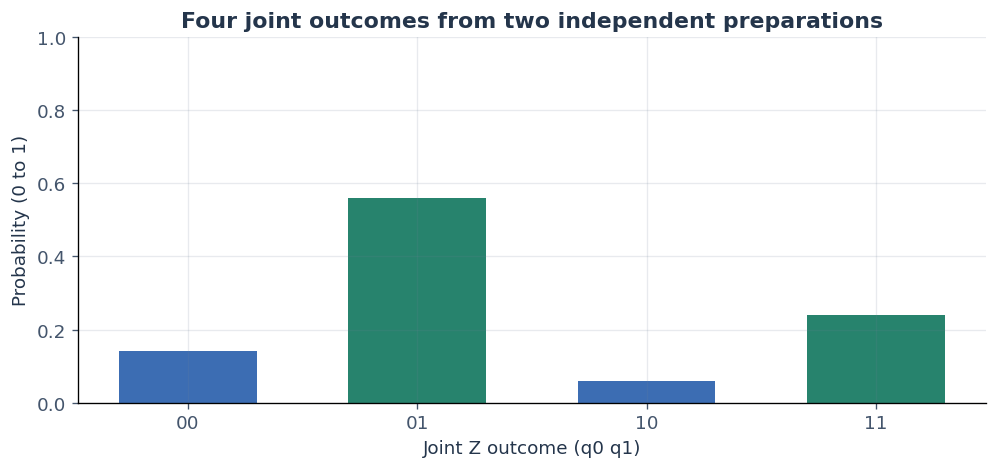

In [2]:
a = assert_state([np.sqrt(0.7), np.sqrt(0.3)])
b = assert_state([np.sqrt(0.2), 1j * np.sqrt(0.8)])
product = assert_state(np.kron(a, b))
predicted_joint = np.outer(probabilities(a), probabilities(b)).reshape(4)
print("Product amplitudes [00, 01, 10, 11]:", np.round(product, 6))
print("Joint Z probabilities:", np.round(probabilities(product), 6))
assert np.allclose(probabilities(product), [0.14, 0.56, 0.06, 0.24])
assert np.allclose(probabilities(product), predicted_joint)
fig, ax = plt.subplots(layout="constrained")
ax.bar(labels, probabilities(product), color=[BLUE, GREEN, BLUE, GREEN], width=0.6)
ax.set(xlabel="Joint Z outcome (q0 q1)", ylabel="Probability (0 to 1)", ylim=(0, 1),
       title="Four joint outcomes from two independent preparations")
plt.show()

## 3. Apply a gate to one named qubit

In the four-entry space, applying H to `q0` means the matrix `H ⊗ I`; applying H to `q1` means `I ⊗ H`. `I` is the identity operation. This makes the target convention explicit.

A **controlled-NOT (CNOT)** with `q0` as control and `q1` as target flips the target only when the control bit is `1`: `00 → 00`, `01 → 01`, `10 → 11`, `11 → 10`. It applies this rule linearly to amplitudes, including superpositions. Read each mapping below to check that you have the ordering right.

In [3]:
def apply_local(state, gate, target):
    state = assert_state(state)
    if state.size != 4 or target not in (0, 1):
        raise ValueError("Specify q0 or q1 in a two-qubit state.")
    if np.shape(gate) != (2, 2) or not np.allclose(gate.conj().T @ gate, I, atol=TOLERANCE, rtol=0):
        raise ValueError("The local gate must be a unitary 2-by-2 matrix.")
    joint_gate = np.kron(gate, I) if target == 0 else np.kron(I, gate)
    return assert_state(joint_gate @ state)


CNOT = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=complex)
basis = np.eye(4, dtype=complex)
initial = np.kron(zero, zero)
print("H on q0 from |00>:", np.round(apply_local(initial, H, 0), 6))
print("H on q1 from |00>:", np.round(apply_local(initial, H, 1), 6))
mappings = []
for index, state in enumerate(basis):
    output_index = int(np.argmax(probabilities(CNOT @ state)))
    mappings.append(output_index)
    print(f"CNOT: {labels[index]} -> {labels[output_index]}")
assert mappings == [0, 1, 3, 2]
assert np.allclose(CNOT.conj().T @ CNOT, np.eye(4))

H on q0 from |00>: [0.707107+0.j 0.      +0.j 0.707107+0.j 0.      +0.j]
H on q1 from |00>: [0.707107+0.j 0.707107+0.j 0.      +0.j 0.      +0.j]
CNOT: 00 -> 00
CNOT: 01 -> 01
CNOT: 10 -> 11
CNOT: 11 -> 10


## 4. Prepare a Bell state and read each qubit's marginal

From `|00⟩`, apply H to `q0`, then CNOT. The state becomes `|Φ+⟩ = (|00⟩ + |11⟩)/sqrt(2)`, pronounced **phi plus**. The two nonzero amplitudes have a coherent relative phase of zero.

A **marginal probability** ignores the other qubit's result. For `q0`, sum the joint probabilities in each row of the `2 × 2` probability table; for `q1`, sum each column. Thus `P(q0 = 0) = P(00) + P(01)`. Each qubit of this Bell state is locally fifty-fifty, although the joint Z results always match.

Compare with `|+⟩ ⊗ |+⟩`. It has the same local Z marginals but four equally likely joint Z outcomes. Local marginals alone do not specify a joint state.

Bell: joint Z [0.5 0.  0.  0.5]; q0 [0.5 0.5]; q1 [0.5 0.5]
Independent plus: joint Z [0.25 0.25 0.25 0.25]; q0 [0.5 0.5]; q1 [0.5 0.5]


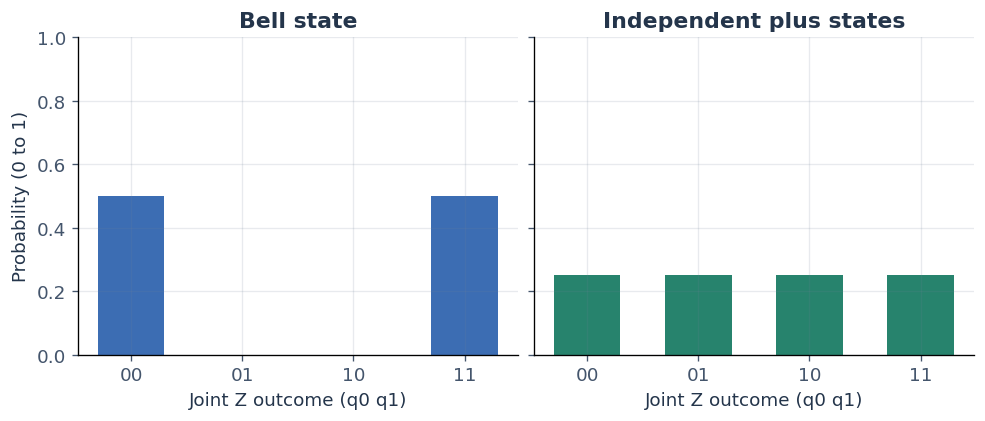

In [4]:
def marginals(distribution):
    table = np.asarray(distribution).reshape(2, 2)
    return table.sum(axis=1), table.sum(axis=0)


bell = assert_state(CNOT @ apply_local(initial, H, 0))
plus = H @ zero
independent_plus = assert_state(np.kron(plus, plus))
assert np.allclose(bell, [1 / np.sqrt(2), 0, 0, 1 / np.sqrt(2)])
for name, state in [("Bell", bell), ("Independent plus", independent_plus)]:
    joint_p = probabilities(state)
    q0_p, q1_p = marginals(joint_p)
    print(f"{name}: joint Z {np.round(joint_p, 6)}; q0 {np.round(q0_p, 6)}; q1 {np.round(q1_p, 6)}")
    assert np.allclose(q0_p, [0.5, 0.5])
    assert np.allclose(q1_p, [0.5, 0.5])
fig, axes = plt.subplots(1, 2, figsize=(8.1, 3.4), sharey=True, layout="constrained")
for ax, title, state, color in zip(axes, ["Bell state", "Independent plus states"], [bell, independent_plus], [BLUE, GREEN]):
    ax.bar(labels, probabilities(state), color=color, width=0.6)
    ax.set(title=title, xlabel="Joint Z outcome (q0 q1)", ylim=(0, 1))
axes[0].set_ylabel("Probability (0 to 1)")
plt.show()

## 5. Separate Bell coherence from classical correlation

A classical correlated source chooses `|00⟩` half the time and `|11⟩` half the time. It has exactly the Bell state's Z/Z probabilities, so matching Z bits alone does not demonstrate entanglement.

For X/X, apply H locally to each qubit before calculating Z probabilities. Output labels `++`, `+−`, `−+`, `−−` replace `00`, `01`, `10`, `11` in the same order. The Bell state still gives matching results; the classical mixture gives all four combinations equally often. Averaging branch probabilities is essential: summing the branch amplitudes would incorrectly make a Bell state.

This calculation distinguishes **these two named preparations**. It is not a general-purpose entanglement certificate from two arbitrary datasets, and it does not calculate a Bell inequality.

Bell Z/Z: [0.5 0.  0.  0.5] ; mixture Z/Z: [0.5 0.  0.  0.5]
Bell X/X: [0.5 0.  0.  0.5] ; mixture X/X: [0.25 0.25 0.25 0.25]


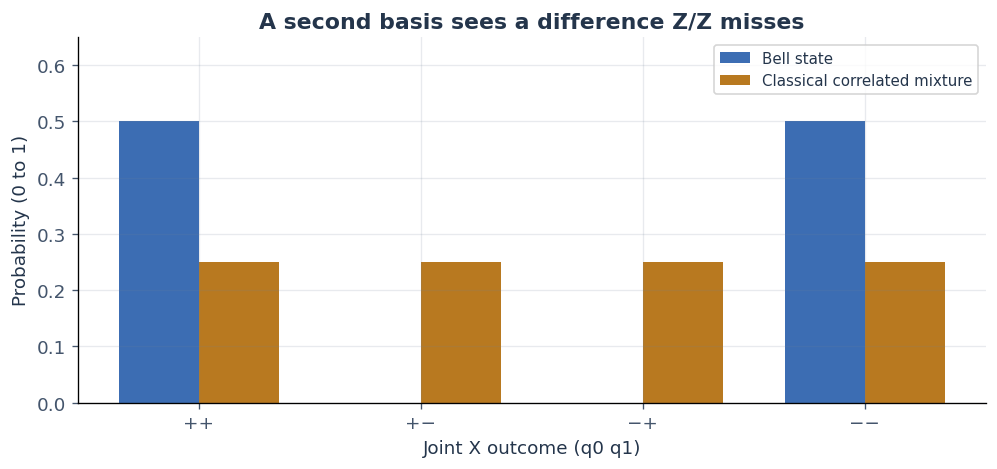

In [5]:
def basis_probabilities(state, bases=("Z", "Z")):
    transformed = assert_state(state)
    if len(bases) != 2 or any(basis not in ("X", "Z") for basis in bases):
        raise ValueError("Choose X or Z for each of the two qubits.")
    for target, basis_name in enumerate(bases):
        if basis_name == "X":
            transformed = apply_local(transformed, H, target)
    return probabilities(transformed)


classical_branches = [(0.5, basis[0]), (0.5, basis[3])]


def mixture_probabilities(bases=("Z", "Z")):
    return sum(weight * basis_probabilities(state, bases) for weight, state in classical_branches)


bell_zz, bell_xx = basis_probabilities(bell), basis_probabilities(bell, ("X", "X"))
mixture_zz, mixture_xx = mixture_probabilities(), mixture_probabilities(("X", "X"))
print("Bell Z/Z:", np.round(bell_zz, 6), "; mixture Z/Z:", np.round(mixture_zz, 6))
print("Bell X/X:", np.round(bell_xx, 6), "; mixture X/X:", np.round(mixture_xx, 6))
assert np.allclose(bell_zz, mixture_zz)
assert np.allclose(bell_xx, [0.5, 0, 0, 0.5])
assert np.allclose(mixture_xx, [0.25, 0.25, 0.25, 0.25])
fig, ax = plt.subplots(layout="constrained")
positions = np.arange(4)
ax.bar(positions - 0.18, bell_xx, width=0.36, color=BLUE, label="Bell state")
ax.bar(positions + 0.18, mixture_xx, width=0.36, color=AMBER, label="Classical correlated mixture")
ax.set(xticks=positions, xticklabels=["++", "+−", "−+", "−−"], xlabel="Joint X outcome (q0 q1)",
       ylabel="Probability (0 to 1)", ylim=(0, 0.65), title="A second basis sees a difference Z/Z misses")
ax.legend(fontsize=9)
plt.show()

## 6. Check whether a known pure state factors

For a known **pure** two-qubit state, arrange its amplitudes in the coefficient matrix `A = [[c00, c01], [c10, c11]]`. If the state factors as `a ⊗ b`, the rows are proportional and `det(A) = c00 c11 − c01 c10 = 0`. Conversely a nonzero normalized pure two-qubit state with zero determinant has rank one and can be factored. A nonzero determinant therefore diagnoses entanglement for this exact pure-state model.

This is an amplitude calculation using knowledge of the full pure state. It cannot be applied directly to a histogram, and it does not classify an arbitrary mixed preparation. In particular the classical source is an ensemble, not a four-entry coherent amplitude vector.

In [6]:
for name, state in [("Unequal product", product), ("Independent plus", independent_plus), ("Bell", bell)]:
    coefficient_matrix = state.reshape(2, 2)
    determinant = np.linalg.det(coefficient_matrix)
    print(f"{name:17s}: amplitude-matrix determinant {determinant.real:+.6f}{determinant.imag:+.6f}i")
assert np.isclose(np.linalg.det(product.reshape(2, 2)), 0)
assert np.isclose(np.linalg.det(independent_plus.reshape(2, 2)), 0)
assert np.isclose(abs(np.linalg.det(bell.reshape(2, 2))), 0.5)
print("The Bell amplitudes cannot be written as a product of two single-qubit vectors.")
print("This pure-state test uses amplitudes; the classical mixture is not an input to it.")

Unequal product  : amplitude-matrix determinant +0.000000+0.000000i
Independent plus : amplitude-matrix determinant +0.000000+0.000000i
Bell             : amplitude-matrix determinant +0.500000+0.000000i
The Bell amplitudes cannot be written as a product of two single-qubit vectors.
This pure-state test uses amplitudes; the classical mixture is not an input to it.


## 7. Check no-signalling under local gates

Name the `q0` observer **Alice** and the `q1` observer **Bob**. Alice can change a joint correlation by operating on her own qubit, but a deterministic local unitary cannot change Bob's marginal distribution. Bob cannot infer which gate Alice chose from his own outcomes alone.

Test this numerically for the Bell state and for a second, asymmetric complex state. Test Bob's Z and X measurements while Alice chooses X, H, Ry, or Rz. This avoids concluding no-signalling from the Bell state's symmetric Z histogram alone.

Why does this hold generally? For each fixed Bob basis outcome, Alice's gate transforms the two corresponding amplitudes by a unitary matrix; their summed squared magnitude is preserved. These finite examples check the implementation of that argument. They are not a test of communication hardware.

In [7]:
def Ry(theta):
    c, s = np.cos(theta / 2), np.sin(theta / 2)
    return np.array([[c, -s], [s, c]], dtype=complex)


def Rz(phi):
    return np.diag([np.exp(-0.5j * phi), np.exp(0.5j * phi)])


asymmetric = np.array([1, 2j, -0.5, 0.3j], dtype=complex)
asymmetric = assert_state(asymmetric / np.linalg.norm(asymmetric))
alice_choices = {"X": X, "H": H, "Ry(0.73)": Ry(0.73), "Rz(1.11)": Rz(1.11)}
largest_change = 0.0
for state_name, state in [("Bell", bell), ("Asymmetric", asymmetric)]:
    for bob_basis in ["Z", "X"]:
        reference = marginals(basis_probabilities(state, ("Z", bob_basis)))[1]
        print(f"{state_name:10s}, Bob {bob_basis}: original marginal {np.round(reference, 6)}")
        for gate in alice_choices.values():
            changed = apply_local(state, gate, 0)
            after = marginals(basis_probabilities(changed, ("Z", bob_basis)))[1]
            difference = np.max(np.abs(after - reference))
            largest_change = max(largest_change, difference)
            assert difference < TOLERANCE
print(f"Largest Bob-marginal change over all tested Alice gates: {largest_change:.3e}")
print("Numerical precision only: no local choice changed Bob's unconditioned distribution.")

Bell      , Bob Z: original marginal [0.5 0.5]
Bell      , Bob X: original marginal [0.5 0.5]
Asymmetric, Bob Z: original marginal [0.234082 0.765918]
Asymmetric, Bob X: original marginal [0.5 0.5]
Largest Bob-marginal change over all tested Alice gates: 1.665e-16
Numerical precision only: no local choice changed Bob's unconditioned distribution.


## 8. Contrast conditional information with an ignored measurement

If Alice measures Z on the Bell state and knows outcome `0`, the conditional joint state is `|00⟩` and Bob's Z result is certain to be `0`. If she gets `1`, the conditional state is `|11⟩`. Each branch happens with probability `0.5`.

Without receiving Alice's result, Bob must average the branches and still predicts `[0.5, 0.5]`. Alice cannot choose the random result to encode a message. Sorting Bob's data by Alice's results requires an ordinary communication channel.

The helper below computes both possible projections explicitly. It is a conditional-state calculation, not a second independent preparation or a forceful choice of measurement outcome.

In [8]:
def alice_z_branch(state, outcome):
    state = assert_state(state)
    keep = np.array([int(label[0]) == outcome for label in labels])
    probability = probabilities(state)[keep].sum()
    if probability <= 0:
        raise ValueError("Cannot condition on an impossible result.")
    post = np.where(keep, state, 0) / np.sqrt(probability)
    return probability, assert_state(post)


bob_average = np.zeros(2)
for outcome in [0, 1]:
    weight, post = alice_z_branch(bell, outcome)
    bob_conditional = marginals(probabilities(post))[1]
    bob_average += weight * bob_conditional
    print(f"Alice outcome {outcome}: branch probability {weight:.1f}; Bob's conditional Z {np.round(bob_conditional, 6)}")
    assert np.isclose(bob_conditional[outcome], 1)
print("Bob without Alice's result:", np.round(bob_average, 6))
assert np.allclose(bob_average, [0.5, 0.5])
print("Conditioned predictions change; the unconditioned marginal does not.")

Alice outcome 0: branch probability 0.5; Bob's conditional Z [1. 0.]
Alice outcome 1: branch probability 0.5; Bob's conditional Z [0. 1.]
Bob without Alice's result: [0.5 0.5]
Conditioned predictions change; the unconditioned marginal does not.


## 9. Sample joint outcomes and calculate a correlation

For binary outcomes assign value `+1` to `0` or `+`, and `−1` to `1` or `−`. The correlation `C` is the average product of the two values: `C = P(same) − P(different)`. Thus perfect matching gives `+1`, perfect opposition gives `−1`, and these equally likely independent outcomes give `0`.

Estimate X/X distributions from `800` fresh pairs per preparation. A multinomial draw samples counts from the exact joint distribution. The Bell model forbids unlike X results here, while the classical mixture samples all four. Finite-shot counts fluctuate; a measured correlation alone does not establish the full state or a Bell violation.

Bell: X/X counts [398   0   0 402]
Bell: exact C 1.0000; sampled C 1.0000
Mixture: X/X counts [212 187 195 206]
Mixture: exact C 0.0000; sampled C 0.0450


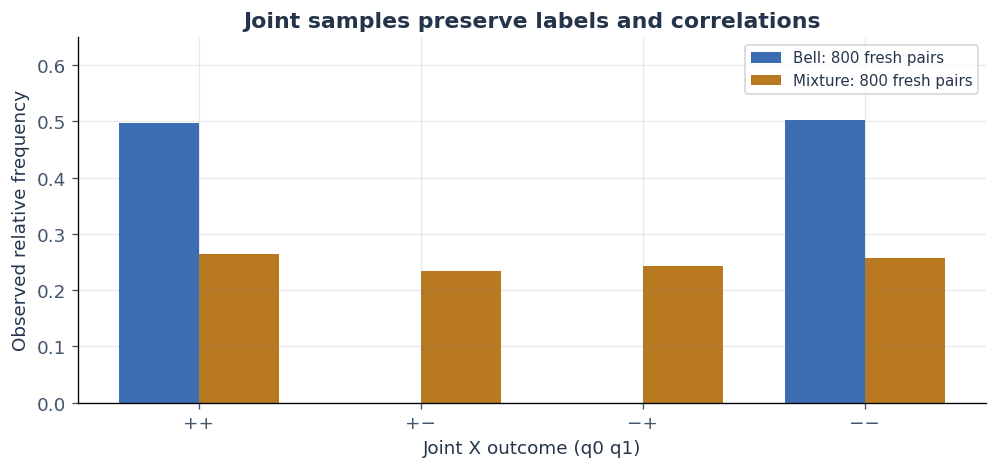

In [9]:
rng = np.random.default_rng(20261016)
shots = 800
sign_products = np.array([1, -1, -1, 1])
bell_counts = rng.multinomial(shots, bell_xx)
mixture_counts = rng.multinomial(shots, mixture_xx)
for name, exact, counts in [("Bell", bell_xx, bell_counts), ("Mixture", mixture_xx, mixture_counts)]:
    estimated = counts / shots
    print(f"{name}: X/X counts {counts}")
    print(f"{name}: exact C {exact @ sign_products:.4f}; sampled C {estimated @ sign_products:.4f}")
    assert counts.sum() == shots
assert bell_counts[1] == 0 and bell_counts[2] == 0
assert np.isclose(bell_xx @ sign_products, 1)
assert np.isclose(mixture_xx @ sign_products, 0)
fig, ax = plt.subplots(layout="constrained")
locations = np.arange(4)
ax.bar(locations - 0.18, bell_counts / shots, 0.36, color=BLUE, label="Bell: 800 fresh pairs")
ax.bar(locations + 0.18, mixture_counts / shots, 0.36, color=AMBER, label="Mixture: 800 fresh pairs")
ax.set(xticks=locations, xticklabels=["++", "+−", "−+", "−−"], xlabel="Joint X outcome (q0 q1)",
       ylabel="Observed relative frequency", ylim=(0, 0.65), title="Joint samples preserve labels and correlations")
ax.legend(fontsize=9)
plt.show()

## 10. Find entanglement the chosen comparison misses

Change the Bell state's relative phase: `|ψ(φ)⟩ = (|00⟩ + exp(iφ)|11⟩)/sqrt(2)`. Every state in this family is entangled: its pure-state coefficient determinant has magnitude `0.5`. Every Z/Z distribution still has probabilities `[0.5, 0, 0, 0.5]`.

The X/X correlation is now `C = cos φ`. At `φ = 90°`, the X/X distribution becomes `[0.25, 0.25, 0.25, 0.25]`, exactly like the classical correlated mixture. Our Z/Z plus X/X comparison misses the phase-sensitive entanglement in this example. Additional measurement settings or a different justified witness would be needed; do not label every state with `C = 0` as unentangled.

At relative phase 90°:
Z/Z probabilities: [0.5 0.  0.  0.5]
X/X probabilities: [0.25 0.25 0.25 0.25]
Pure-state determinant magnitude: 0.5


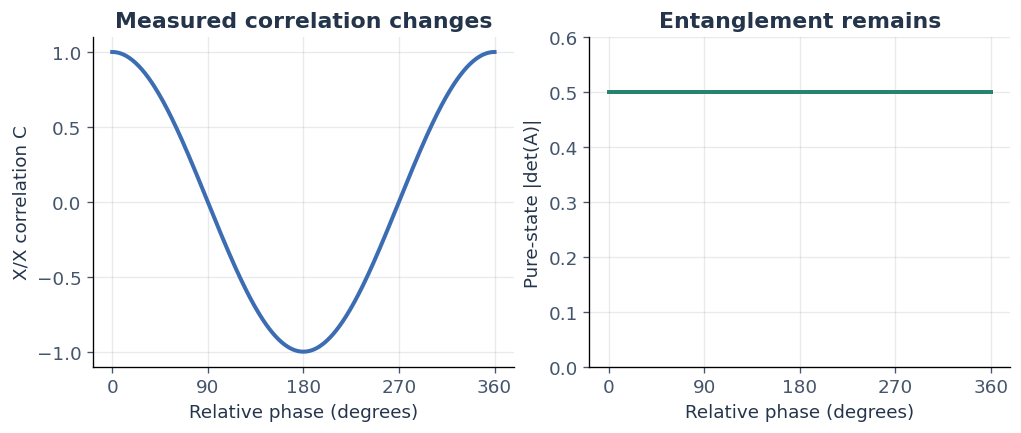

All checks passed: basis ordering, Bell preparation, ensemble comparison, marginals, and the comparison's limitation.


In [10]:
phases = np.linspace(0, 2 * np.pi, 361)
correlations, determinant_magnitudes = [], []
for phi in phases:
    phased_bell = assert_state([1 / np.sqrt(2), 0, 0, np.exp(1j * phi) / np.sqrt(2)])
    correlations.append(basis_probabilities(phased_bell, ("X", "X")) @ sign_products)
    determinant_magnitudes.append(abs(np.linalg.det(phased_bell.reshape(2, 2))))
assert np.allclose(correlations, np.cos(phases))
assert np.allclose(determinant_magnitudes, 0.5)
hidden = assert_state([1 / np.sqrt(2), 0, 0, 1j / np.sqrt(2)])
print("At relative phase 90°:")
print("Z/Z probabilities:", np.round(basis_probabilities(hidden), 6))
print("X/X probabilities:", np.round(basis_probabilities(hidden, ("X", "X")), 6))
print("Pure-state determinant magnitude:", round(abs(np.linalg.det(hidden.reshape(2, 2))), 6))
assert np.allclose(basis_probabilities(hidden), mixture_zz)
assert np.allclose(basis_probabilities(hidden, ("X", "X")), mixture_xx)
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.5), layout="constrained")
axes[0].plot(np.rad2deg(phases), correlations, color=BLUE)
axes[0].set(xlabel="Relative phase (degrees)", ylabel="X/X correlation C", ylim=(-1.1, 1.1),
            xticks=[0, 90, 180, 270, 360], title="Measured correlation changes")
axes[1].plot(np.rad2deg(phases), determinant_magnitudes, color=GREEN)
axes[1].set(xlabel="Relative phase (degrees)", ylabel="Pure-state |det(A)|", ylim=(0, 0.6),
            xticks=[0, 90, 180, 270, 360], title="Entanglement remains")
plt.show()
print("All checks passed: basis ordering, Bell preparation, ensemble comparison, marginals, and the comparison's limitation.")

**Try a change locally:** prepare `sqrt(0.2)|00⟩ + exp(iφ)sqrt(0.8)|11⟩` instead of equal amplitudes. Predict Z/Z probabilities and both qubits' Z marginals. At `φ = 60°`, predict `C_XX = 2 sqrt(0.2 × 0.8) cos(60°) = 0.4`, then verify numerically. Does changing Alice's local gate change Bob's unconditioned marginal?

**Take this with you:** tensor products attach amplitudes to ordered joint outcomes. Product states, entangled pure states, and classical mixtures are different descriptions. A Bell state has nonlocal correlations but no controllable faster-than-light signalling. A chosen set of measurements can expose coherence in one case and miss it in another.

References: [IBM, multiple systems](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/multiple-systems); [Bell, On the Einstein Podolsky Rosen paradox (1964)](https://doi.org/10.1103/PhysicsPhysiqueFizika.1.195). This notebook does not evaluate the inequality in that paper.